# Exercise: The Higgs Boson Discovery

**The Scenario:**
It is 2012. You are a particle physicist at CERN analyzing data from the Large Hadron Collider. You are searching for the elusive Higgs boson, which theory predicts should decay into pairs of photons. You have just collected your first dataset.

**The Data:**
You are given a dataset containing the invariant mass of photon pairs measured by your detector, ranging from 100 GeV to 150 GeV. The histogram below shows the real data you collected! Your task is to use this spectrum to claim a discovery and measure the mass of the new particle.

**Part 1: Hypothesis Testing via Sideband Fit**
To claim a discovery, you must first estimate the expected number of background events that fall inside the expected signal region, in order to show that the observed data is inconsistent with background-only fluctuations.

Standard Model background processes are known to produce a smoothly falling exponential distribution: $f(m) \propto e^{-\lambda m}$. You decide to look for the Higgs in the **Signal Region: [120, 130] GeV**.

1.  **Create the Sideband Dataset:** Create a "sideband" dataset by masking out all events that fall inside the [120, 130] GeV signal window.
2.  **Fit the Background Shape:** Use `iminuit` and `UnbinnedNLL` to fit the decay parameter $\lambda$ using *only* your sideband data.
    * *N.B.: You must take care to normalise the background PDF in the sideband region: the PDF integral over the two sidebands should be normalised to 1.*
3.  **The Hypothesis Test:**
    * Using your fitted value $\hat{\lambda}$, calculate the expected number of background events ($b$) that should have landed *inside* the [120, 130] GeV signal window. (Hint: This is the total number of events in the sideband multiplied by the ratio of the integrals of the PDF over the signal and sideband regions.)
    * Count the actual number of observed events ($N_{obs}$) that fall inside the signal window.
    * Calculate the Poisson p-value of observing $N_{obs}$ or more events given the expected background $b$. Do you claim a discovery of the Higgs boson with a significance of at least $5\sigma$?



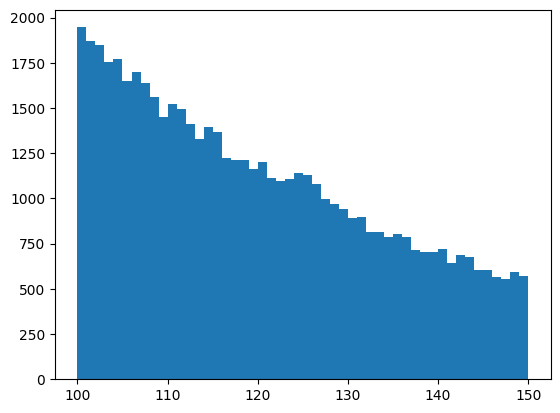

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# The modified Google Drive direct-download link
url = 'https://drive.google.com/uc?export=download&id=1AauqtqMTm5MT4b57NHOnxytsJgBSvhGX'
df = pd.read_csv(url)
data = df['mass_gev']
plt.hist(data, bins=50, range=(100, 150));


In [14]:
!pip install iminuit

In [15]:
import scipy.stats as stats
from scipy.stats import expon
from scipy.integrate import quad
from scipy.stats import norm
import numpy as np
from iminuit import Minuit
from iminuit.cost import UnbinnedNLL

In [16]:

sideband = data[(data <= 120) | (data >= 130)]
sb_regions = [(100, 120), (130, 150)]

def background(x, lam):
    norm = sum(np.exp(-lam * a) - np.exp(-lam * b) for (a, b) in sb_regions)
    return lam * np.exp(-lam * x) / norm


nll = UnbinnedNLL(sideband, background)

# fit
m = Minuit(nll, lam=0.1)
m.limits["lam"] = (0, None)
m.migrad()
m.hesse()
m.minos()

# Display the nice summary table in Jupyter
display(m)

# Extract and print the values programmatically
lam_minos_minus = m.merrors["lam"].lower
lam_minos_plus  = m.merrors["lam"].upper

print(f"Best fit lambda = {m.values['lam']:.5f}")
print(f"MINOS lower error (Δlambda-) = {lam_minos_minus:.5f}")
print(f"MINOS upper error (Δlambda+) = +{lam_minos_plus:.5f}")
#@title { vertical-output: true}

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.222e+05                  │              Nfcn = 30               │
│ EDM = 9.39e-08 (Goal: 0.0002)    │            time = 0.1 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ lam  │ 25.71e-3  │  0.31e-3  │  -0.31e-3  │  0.31e-3   │    0    │         │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┐
│          │          lam          │
├──────────┼───────────┬───────────┤
│  Error   │ -0.31e-3  │  0.31e-3  │
│  Valid   │   True    │   True    │
│ At Limit │   False   │   False   │
│ Max FCN  │   False   │   False   │
│ New Min  │   False   │   False   │
└──────────┴───────────┴───────────┘
┌─────┬──────────┐
│     │      lam │
├─────┼──────────┤
│ lam │ 9.85e-08 │
└─────┴──────────┘

Best fit lambda = 0.02571
MINOS lower error (Δlambda-) = -0.00031
MINOS upper error (Δlambda+) = +0.00031


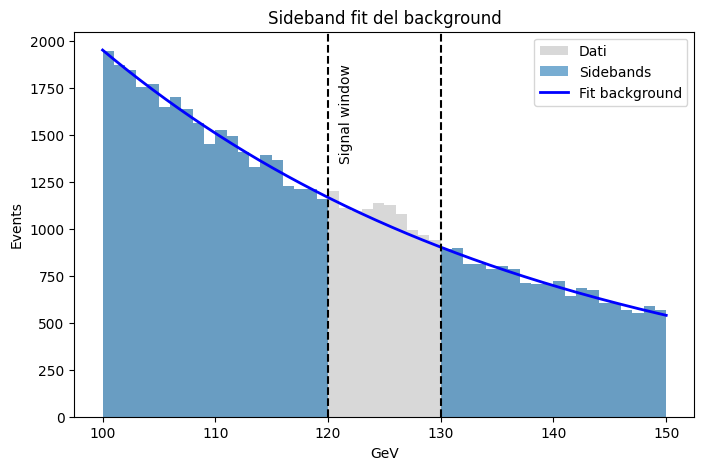

In [17]:
lam = m.values["lam"]
x_plot = np.linspace(100, 150, 1000)
y_plot = background(x_plot, lam)

plt.figure(figsize=(8,5))


plt.hist(data, bins=50, range=(100,150), alpha=0.3, label="Dati", color="gray")
plt.hist(sideband, bins=50, range=(100,150), alpha=0.6, label="Sidebands")


plt.plot(x_plot, y_plot * len(sideband) * (50/50), color="blue", lw=2, label="Fit background")


plt.axvline(120, color="k", linestyle="--")
plt.axvline(130, color="k", linestyle="--")
plt.text(121, max(np.histogram(data, bins=50, range=(100,150))[0])*0.7,
         "Signal window", rotation=90)

plt.xlabel("GeV")
plt.ylabel("Events")
plt.title("Sideband fit del background")
plt.legend()
plt.show()
#@title { vertical-output: true}

In [18]:

# expected number of background events that should have landed inside the [120, 130] GeV signal window.
integral_signal = (np.exp(-lam * 120) - np.exp(-lam * 130))
integral_sideband = sum(np.exp(-lam * a) - np.exp(-lam * b) for (a, b) in sb_regions)
background_expected = len(sideband) * integral_signal/integral_sideband
print("Background expected in [120, 130] Gev:",background_expected)
events_observed = len(data[(data >= 120) & (data <= 130)]) - background_expected
print("Events observed in [120, 130] Gev:",events_observed)

Background expected in [120, 130] Gev: 10293.519374221207
Events observed in [120, 130] Gev: 466.4806257787932


In [19]:
n_obs = len(data[(data >= 120) & (data <= 130)])
b = background_expected
s = 0
model = stats.poisson(mu=b+s)
pval = model.sf(n_obs - 1)  # sf(k-1) = P(X >= k)
print(f'The p-value is {pval:.4%}')

The p-value is 0.0003%


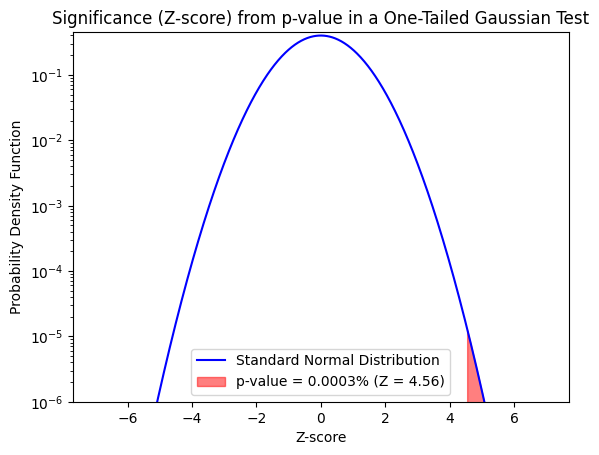

In [20]:

Z_score = norm.ppf(1 - pval)

x = np.linspace(-7, 7, 1000)
plt.plot(x, norm.pdf(x), color='blue', label='Standard Normal Distribution')

x_tail = np.linspace(Z_score, 7, 100)
plt.fill_between(x_tail, 0, norm.pdf(x_tail), color='red', alpha=0.5,
                 label=f'p-value = {pval*100:.4f}% (Z = {Z_score:.2f})')

plt.title('Significance (Z-score) from p-value in a One-Tailed Gaussian Test')
plt.xlabel('Z-score')
plt.ylabel('Probability Density Function')
plt.legend()
plt.yscale('log')
plt.ylim(1e-6, 0.45)
plt.show()
#@title { vertical-output: true}

In [36]:
# PDF: Gaussiana segnale + esponenziale background
xmin, xmax = 100, 150

def pdf_total(x, mH, sigma, mu):

    norm_b = (np.exp(-lam * xmin) - np.exp(-lam * xmax))/lam
    B = np.exp(-lam * x) / norm_b

    norm_s = norm.cdf(xmax, loc=mH, scale=sigma) - norm.cdf(xmin, loc=mH, scale=sigma)
    S =  norm.pdf(x, loc=mH, scale=sigma) / norm_s

    return mu*S + (1-mu)*B # mu tra 0 e 1 come frazione di segnale

nll = UnbinnedNLL(data, pdf_total)

m = Minuit(nll, mH=125, sigma=2.0, mu=0.1)
m.limits["sigma"] = (0.5, 5)
m.limits["mH"] = (110, 140)
m.limits["mu"] = (0, 1)


m.migrad()
m.hesse()
display(m)


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 4.262e+05                  │              Nfcn = 217              │
│ EDM = 2.87e-05 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name  │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ mH    │   125.4   │    0.4    │            │            │   110   │   140   │       │
│ 1 │ sigma │    1.4    │    0.4    │            │            │   0.5   │    5    │       │
│ 2 │ mu    │  0.0071   │  0.0018   │            │            │    0    │    1    │       │
└───┴───────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌───────┬────────────────────────────┐
│       │       mH    sigma       mu │
├───────┼────────────────────────────┤
│    mH │    0.144     0.06 150.4e-6 │
│ sigma │     0.06    0.176 483.0e-6 │
│    mu │ 150.4e-6 483.0e-6 3.24e-06 │
└───────┴────────────────────────────┘